# ArcFace vs Softmax: Understanding Discriminative Embedding Learning

MNIST를 이용해 **일반 Softmax와 ArcFace가 embedding 공간을 어떻게 다르게 학습하는지** 비교한다.

이 노트북에서는 다음을 확인한다.

1. Softmax와 ArcFace의 분류 방식 차이
2. Angular margin의 역할
3. 분류 정확도 비교
4. t-SNE를 이용한 embedding 시각화
5. 같은 class / 다른 class의 cosine similarity 비교

ArcFace의 목적은 단순히 분류 정확도를 높이는 것이 아니라, **구분력이 좋은 embedding을 학습하는 것**에 있다.


In [1]:
import math
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import transforms as T, datasets

from sklearn.manifold import TSNE
from tqdm.notebook import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


device: cuda


## 1. Prepare MNIST

간단한 비교 실험을 위해 MNIST를 사용한다.

각 숫자 class를 하나의 identity처럼 보고, 학습된 embedding의 분포를 비교한다.


In [2]:
train_dataset = datasets.MNIST(
    root="./sample_data",
    train=True,
    transform=T.ToTensor(),
    download=True,
)

test_dataset = datasets.MNIST(
    root="./sample_data",
    train=False,
    transform=T.ToTensor(),
    download=True,
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

print("train:", len(train_dataset))
print("test :", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 517kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.73MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.97MB/s]

train: 60000
test : 10000


## 2. Standard Softmax Classification

일반적인 linear classifier는 embedding \(x\)에 대해

$$ z_j = W_j^T x + b_j $$

를 계산한다.

Cross Entropy는 정답 class의 logit이 다른 class보다 커지도록 학습한다.

하지만 **같은 class의 embedding이 각도상 얼마나 가까워야 하는지**를 직접 제한하지는 않는다.


## 3. From Softmax to ArcFace

ArcFace는 embedding과 class weight를 L2 normalize한다.


$$\hat{x}=\frac{x}{\|x\|}, \qquad \hat{W}_j=\frac{W_j}{\|W_j\|}$$


그러면 두 벡터의 내적은


$$\hat{W}_j^T\hat{x} = \cos\theta_j$$


가 되어, class score가 **벡터 사이의 각도**로 결정된다.

정답 class에는


$$\cos\theta_y$$


대신


$$cos(\theta_y+m)$$


을 사용한다.

즉 정답 조건을 더 어렵게 만들어, embedding이 자신의 class 방향에 더 가까워지도록 학습한다.


### A small numerical example

간단한 숫자 예제로 angular margin을 추가했을 때 정답 logit이 어떻게 변하는지 확인한다.

`margin`은 radian 단위이다.


In [3]:
theta_deg = 30
theta = math.radians(theta_deg)
margin = 0.5

cos_theta = math.cos(theta)
cos_theta_margin = math.cos(theta + margin)

print(f"theta                : {theta_deg} degrees")
print(f"margin               : {margin:.3f} rad ({math.degrees(margin):.1f} degrees)")
print(f"cos(theta)           : {cos_theta:.4f}")
print(f"cos(theta + margin)  : {cos_theta_margin:.4f}")
print(f"target-logit decrease: {cos_theta - cos_theta_margin:.4f}")


theta                : 30 degrees
margin               : 0.500 rad (28.6 degrees)
cos(theta)           : 0.8660
cos(theta + margin)  : 0.5203
target-logit decrease: 0.3457


ArcFace는 정답 logit을 일부러 낮춘다.

따라서 loss를 줄이려면 embedding이 정답 class 방향에 더 가까워져야 한다.


## 4. Shared CNN Backbone

두 모델 모두 같은 CNN backbone 구조를 사용한다.

Backbone은 입력 이미지에서 **256차원 embedding**을 추출한다.

차이는 embedding 이후의 classifier에서 발생한다.


In [4]:
class MNISTBackbone(nn.Module):
    def __init__(self, embedding_dim=256):
        super().__init__()

        self.conv1 = nn.Conv2d(1, 32, 5)
        self.conv2 = nn.Conv2d(32, 32, 5)
        self.conv3 = nn.Conv2d(32, 64, 5)

        self.dropout = nn.Dropout(0.25)
        self.maxpool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU(inplace=True)

        self.embedding = nn.Linear(3 * 3 * 64, embedding_dim)

    def forward(self, x):
        x = self.relu(self.conv1(x))
        x = self.dropout(x)

        x = self.relu(self.maxpool(self.conv2(x)))
        x = self.dropout(x)

        x = self.relu(self.maxpool(self.conv3(x)))
        x = self.dropout(x)

        x = x.view(x.size(0), -1)
        x = self.relu(self.embedding(x))
        return x


## 5. Softmax Model

Softmax 모델은 backbone에서 얻은 embedding을 일반적인 `Linear` classifier에 입력한다.


In [5]:
class SoftmaxModel(nn.Module):
    def __init__(self, embedding_dim=256, num_classes=10):
        super().__init__()
        self.backbone = MNISTBackbone(embedding_dim)
        self.classifier = nn.Linear(embedding_dim, num_classes)

    def extract_embedding(self, x, normalize=False):
        embedding = self.backbone(x)
        if normalize:
            embedding = F.normalize(embedding, p=2, dim=1)
        return embedding

    def forward(self, x):
        embedding = self.backbone(x)
        return self.classifier(embedding)


## 6. ArcFace Model

ArcFace에서는 일반 linear logit 대신, 정규화된 embedding과 class weight 사이의 cosine similarity를 사용한다.

정답 class에만 angular margin을 적용한다.

$$
\cos(\theta+m)
=
\cos\theta\cos m-\sin\theta\sin m
$$

여기서는 `arccos`를 직접 사용하지 않고 위 식으로 계산한다.


In [6]:
class ArcFaceHead(nn.Module):
    def __init__(self, embedding_dim=256, num_classes=10, scale=30.0, margin=0.5):
        super().__init__()

        self.scale = scale
        self.margin = margin

        self.weight = nn.Parameter(torch.empty(num_classes, embedding_dim))
        nn.init.xavier_uniform_(self.weight)

        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)

        # Keeps cos(theta + m) monotonic near the boundary.
        self.threshold = math.cos(math.pi - margin)
        self.mm = math.sin(math.pi - margin) * margin

    def cosine_logits(self, embedding):
        embedding = F.normalize(embedding, p=2, dim=1)
        weight = F.normalize(self.weight, p=2, dim=1)
        return F.linear(embedding, weight)

    def forward(self, embedding, labels=None):
        cosine = self.cosine_logits(embedding)

        # During inference we do not know the target label, so no margin is applied.
        if labels is None:
            return cosine * self.scale

        cosine = torch.clamp(cosine, -1.0 + 1e-7, 1.0 - 1e-7)
        sine = torch.sqrt(torch.clamp(1.0 - cosine.pow(2), min=1e-7))

        phi = cosine * self.cos_m - sine * self.sin_m
        phi = torch.where(cosine > self.threshold, phi, cosine - self.mm)

        one_hot = F.one_hot(labels, num_classes=cosine.size(1)).float()
        logits = one_hot * phi + (1.0 - one_hot) * cosine

        return logits * self.scale


class ArcFaceModel(nn.Module):
    def __init__(self, embedding_dim=256, num_classes=10, scale=30.0, margin=0.5):
        super().__init__()
        self.backbone = MNISTBackbone(embedding_dim)
        self.head = ArcFaceHead(
            embedding_dim=embedding_dim,
            num_classes=num_classes,
            scale=scale,
            margin=margin,
        )

    def extract_embedding(self, x, normalize=False):
        embedding = self.backbone(x)
        if normalize:
            embedding = F.normalize(embedding, p=2, dim=1)
        return embedding

    def forward(self, x, labels=None):
        embedding = self.backbone(x)
        return self.head(embedding, labels)


## 7. Training and Evaluation

ArcFace 학습 시에는 정답 class에 margin을 적용해야 하므로 label을 함께 전달한다.

반면 평가 시에는 정답 label을 모델에 넣지 않고, 일반 cosine logits만 사용해 prediction을 계산한다.


In [7]:
def train_softmax_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)


def train_arcface_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0.0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        logits = model(images, labels)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    total_loss = 0.0
    correct = 0
    criterion = nn.CrossEntropyLoss()

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        # No labels are passed to either model at evaluation time.
        logits = model(images)
        loss = criterion(logits, labels)

        total_loss += loss.item() * images.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()

    return total_loss / len(loader.dataset), correct / len(loader.dataset)


### Train the Softmax baseline

일반 Softmax 모델을 학습한다.


In [8]:
softmax_model = SoftmaxModel().to(device)

criterion = nn.CrossEntropyLoss()
softmax_optimizer = optim.Adam(softmax_model.parameters(), lr=1e-4)

epochs = 10
softmax_history = []

for epoch in range(epochs):
    train_loss = train_softmax_epoch(
        softmax_model,
        train_loader,
        softmax_optimizer,
        criterion,
    )
    val_loss, val_acc = evaluate(softmax_model, test_loader)

    softmax_history.append((train_loss, val_loss, val_acc))
    print(
        f"[Softmax] epoch {epoch + 1:02d} | "
        f"train loss {train_loss:.4f} | "
        f"val loss {val_loss:.4f} | "
        f"val acc {val_acc:.4f}"
    )


[Softmax] epoch 01 | train loss 0.5116 | val loss 0.1333 | val acc 0.9599
[Softmax] epoch 02 | train loss 0.1438 | val loss 0.0730 | val acc 0.9774
[Softmax] epoch 03 | train loss 0.0980 | val loss 0.0541 | val acc 0.9824
[Softmax] epoch 04 | train loss 0.0783 | val loss 0.0453 | val acc 0.9859
[Softmax] epoch 05 | train loss 0.0647 | val loss 0.0357 | val acc 0.9893
[Softmax] epoch 06 | train loss 0.0560 | val loss 0.0314 | val acc 0.9901
[Softmax] epoch 07 | train loss 0.0510 | val loss 0.0280 | val acc 0.9912
[Softmax] epoch 08 | train loss 0.0445 | val loss 0.0258 | val acc 0.9917
[Softmax] epoch 09 | train loss 0.0402 | val loss 0.0274 | val acc 0.9911
[Softmax] epoch 10 | train loss 0.0369 | val loss 0.0241 | val acc 0.9915


### Train the ArcFace model

같은 backbone 구조를 사용하되, classifier만 ArcFace 방식으로 학습한다.


In [9]:
# Re-seed before model creation so that this experiment is reproducible.
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

arcface_model = ArcFaceModel(
    embedding_dim=256,
    num_classes=10,
    scale=30.0,
    margin=0.5,
).to(device)

arcface_optimizer = optim.Adam(arcface_model.parameters(), lr=1e-4)

arcface_history = []

for epoch in range(epochs):
    train_loss = train_arcface_epoch(
        arcface_model,
        train_loader,
        arcface_optimizer,
        criterion,
    )
    val_loss, val_acc = evaluate(arcface_model, test_loader)

    arcface_history.append((train_loss, val_loss, val_acc))
    print(
        f"[ArcFace] epoch {epoch + 1:02d} | "
        f"train loss {train_loss:.4f} | "
        f"val loss {val_loss:.4f} | "
        f"val acc {val_acc:.4f}"
    )


[ArcFace] epoch 01 | train loss 4.9603 | val loss 0.1493 | val acc 0.9809
[ArcFace] epoch 02 | train loss 0.9698 | val loss 0.0965 | val acc 0.9884
[ArcFace] epoch 03 | train loss 0.6543 | val loss 0.0864 | val acc 0.9906
[ArcFace] epoch 04 | train loss 0.5081 | val loss 0.0699 | val acc 0.9922
[ArcFace] epoch 05 | train loss 0.4341 | val loss 0.0775 | val acc 0.9921
[ArcFace] epoch 06 | train loss 0.3820 | val loss 0.0678 | val acc 0.9936
[ArcFace] epoch 07 | train loss 0.3427 | val loss 0.0649 | val acc 0.9936
[ArcFace] epoch 08 | train loss 0.3184 | val loss 0.0640 | val acc 0.9946
[ArcFace] epoch 09 | train loss 0.3041 | val loss 0.0685 | val acc 0.9937
[ArcFace] epoch 10 | train loss 0.2778 | val loss 0.0650 | val acc 0.9943


## 8. Classification Accuracy Comparison

MNIST는 비교적 쉬운 분류 문제이므로 두 모델 모두 높은 정확도가 나올 수 있다.

ArcFace의 핵심 목적은 분류 정확도 자체보다 **embedding의 구분력**을 높이는 것이다.


In [10]:
softmax_val_loss, softmax_val_acc = evaluate(softmax_model, test_loader)
arcface_val_loss, arcface_val_acc = evaluate(arcface_model, test_loader)

classification_results = pd.DataFrame(
    {
        "Model": ["Softmax", "ArcFace"],
        "Validation Loss": [softmax_val_loss, arcface_val_loss],
        "Validation Accuracy": [softmax_val_acc, arcface_val_acc],
    }
)

classification_results


,Model,Validation Loss,Validation Accuracy
0,Softmax,0.024066,0.9915
1,ArcFace,0.064959,0.9943


## 9. Extract Embeddings

두 모델의 backbone에서 256차원 embedding을 직접 추출한다.

Cosine similarity 비교를 위해 embedding은 L2 normalize한다.


In [11]:
@torch.no_grad()
def collect_embeddings(model, loader):
    model.eval()

    embeddings = []
    labels = []

    for images, batch_labels in loader:
        images = images.to(device)

        embedding = model.extract_embedding(images, normalize=True)

        embeddings.append(embedding.cpu())
        labels.append(batch_labels)

    return torch.cat(embeddings, dim=0), torch.cat(labels, dim=0)


softmax_embeddings, embedding_labels = collect_embeddings(softmax_model, test_loader)
arcface_embeddings, _ = collect_embeddings(arcface_model, test_loader)

print("Softmax embeddings:", softmax_embeddings.shape)
print("ArcFace embeddings:", arcface_embeddings.shape)


Softmax embeddings: torch.Size([10000, 256])
ArcFace embeddings: torch.Size([10000, 256])


## 10. t-SNE Visualization of the Embedding Space

두 모델의 embedding을 t-SNE로 2차원에 시각화한다.

t-SNE는 전체 거리 구조를 완전히 보존하지 않으므로, **정성적인 비교용**으로만 사용한다.


In [12]:
num_tsne_samples = min(3000, len(embedding_labels))
rng = np.random.default_rng(SEED)
tsne_indices = rng.choice(len(embedding_labels), size=num_tsne_samples, replace=False)

softmax_tsne_input = softmax_embeddings[tsne_indices].numpy()
arcface_tsne_input = arcface_embeddings[tsne_indices].numpy()
tsne_labels = embedding_labels[tsne_indices].numpy()

softmax_tsne = TSNE(
    n_components=2,
    perplexity=40,
    init="pca",
    learning_rate="auto",
    random_state=SEED,
).fit_transform(softmax_tsne_input)

arcface_tsne = TSNE(
    n_components=2,
    perplexity=40,
    init="pca",
    learning_rate="auto",
    random_state=SEED,
).fit_transform(arcface_tsne_input)


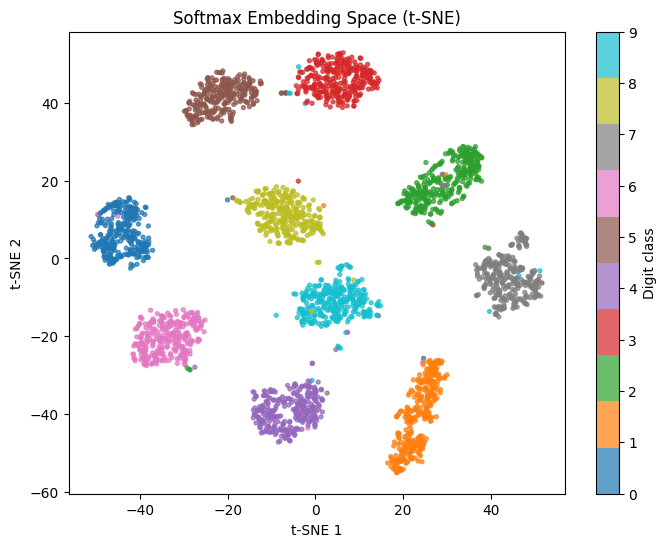

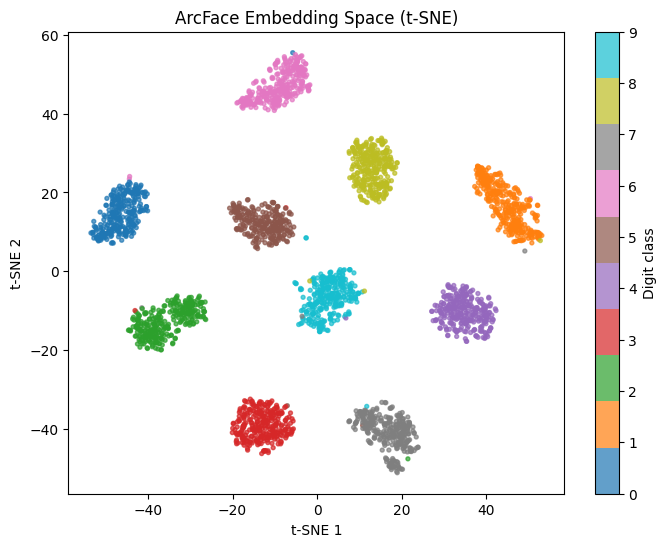

In [13]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    softmax_tsne[:, 0],
    softmax_tsne[:, 1],
    c=tsne_labels,
    s=8,
    alpha=0.7,
    cmap="tab10",
)
plt.title("Softmax Embedding Space (t-SNE)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.colorbar(scatter, ticks=range(10), label="Digit class")
plt.show()

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    arcface_tsne[:, 0],
    arcface_tsne[:, 1],
    c=tsne_labels,
    s=8,
    alpha=0.7,
    cmap="tab10",
)
plt.title("ArcFace Embedding Space (t-SNE)")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.colorbar(scatter, ticks=range(10), label="Digit class")
plt.show()


## 11. Same-Class vs Different-Class Cosine Similarity

t-SNE만으로 판단하지 않고, 실제 embedding 공간에서 cosine similarity를 비교한다.

- 같은 class끼리의 평균 cosine similarity
- 다른 class끼리의 평균 cosine similarity
- 두 값의 차이(Gap)

를 계산한다.


In [14]:
def sampled_cosine_statistics(embeddings, labels, num_pairs=100_000, seed=42):
    generator = torch.Generator().manual_seed(seed)

    n = embeddings.size(0)
    idx1 = torch.randint(0, n, (num_pairs,), generator=generator)
    idx2 = torch.randint(0, n, (num_pairs,), generator=generator)

    valid = idx1 != idx2
    idx1 = idx1[valid]
    idx2 = idx2[valid]

    similarities = (embeddings[idx1] * embeddings[idx2]).sum(dim=1)
    same_class = labels[idx1] == labels[idx2]

    same_mean = similarities[same_class].mean().item()
    different_mean = similarities[~same_class].mean().item()

    return {
        "Same-class cosine": same_mean,
        "Different-class cosine": different_mean,
        "Gap": same_mean - different_mean,
        "Sampled pairs": int(similarities.numel()),
    }


softmax_stats = sampled_cosine_statistics(
    softmax_embeddings,
    embedding_labels,
    seed=SEED,
)

arcface_stats = sampled_cosine_statistics(
    arcface_embeddings,
    embedding_labels,
    seed=SEED,
)

embedding_results = pd.DataFrame(
    [softmax_stats, arcface_stats],
    index=["Softmax", "ArcFace"],
)

embedding_results


,Same-class cosine,Different-class cosine,Gap,Sampled pairs
Softmax,0.844330,0.490579,0.353751,99990
ArcFace,0.937416,0.017222,0.920194,99990


## 12. Interpretation

분류 정확도와 embedding 품질은 서로 다른 관점이다.

- **Classification accuracy**: 정답 class를 맞히는가?
- **Embedding quality**: 같은 class는 가깝고 다른 class는 잘 분리되는가?

ArcFace는 정답 class에 angular margin을 추가해 더 엄격한 조건으로 학습한다.

따라서 얼굴 인식처럼 최종적으로 embedding 간 cosine similarity를 사용하는 문제에서 특히 의미가 있다.
